# 9. Diels-Alder Reaction: Intrinsic Reaction Coordinates

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4/blob/main/book/09-DielsAlder/091-DielsAlder.ipynb)
:::

One of the most **useful** activities in computational chemistry is examining **reaction energy barriers**. If we can compare the energy of a **transition state** as we change structure, we can learn the reasons for these **kinetic** effects and make predictions. Calculating transition state structure and energy is **challenging**. Partially formed bonds and separated charges require **higher levels** of theory to accurately describe and so the computation **cost** rises rapidly. The T.S. itself may not be easy to find, especially when there are high degrees of freedom (lots of ways to arrange the structure).

So let us start with a common example, the **Diels-Alder reaction**. This pericyclic addition reaction is a good candidate for these calculations because of its **organized** transition state (fewer degrees of freedom) and lack of charge separation. We will perform a reaction coordinate **scan** in hopes of **finding** a structure that is **close** to the transition state. We will then perform a Hessian calculation to confirm the presence of an **imaginary vibration**. If we have an imaginary vibration, we have a direction towards the transition state. We will then perform a **saddle point optimization** to find the transition state. Finally, we will perform an **intrinsic reaction coordinate** calculation to calculate the path from the transition state to the ground-state reactants on either side.

## Learning Goals

This exercise will hopefully accomplish the following goals while learning new skills:
-	We will **build** a symmetrical molecule (*C<sub>s</sub>* cyclohexene) from its symmetry-unique atoms using a few lines of *Python*.
-	We will **scan** a reaction coordinate by holding two bond lengths at a series of values with the *Psi4* optimizer's `ranged_distance` constraint.
-	We will find the **imaginary vibration** near the top of the scan and **optimize** the transition state.
-	We will follow the **intrinsic reaction coordinate** (IRC) downhill in both directions from the transition state.
-	We will assemble the whole path, **plot** the energy and the bond lengths along it, and **make a movie** of the reaction.

```{note}
This chapter has two parts. This notebook runs all the calculations. The [second notebook](092-ScanData.ipynb) loads the scan results and works through processing, plotting and fitting the energy profile with *pandas* and *Matplotlib*.
```

In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

# geomeTRIC is a second geometry optimizer that Psi4 can use.
# It is a separate conda package.
try:
    import geometric
except ImportError:
    if IN_COLAB:
        !mamba install -q -y -c conda-forge geometric
    import geometric

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style sheets from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/S2_classic2.mplstyle

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    plt.style.use("../../styles/tufte.mplstyle")

## Setting Up the Notebook

Every *Psi4* notebook begins the same way. We **import** the *Python* packages that we need and tell *Psi4* how much of the computer it may use.

The imports are in the **first code cell** of the notebook. It is hidden on this web page, but you will see it when you open the notebook in *Jupyter*, *Visual Studio Code* or *Google Colab*. It loads these packages...

| Package | What it does |
| :---- | :---- |
| `import psi4` | Loads *Psi4*. Everything *Psi4* can do is now available as `psi4.something`. |
| `import geometric` | Checks that *geomeTRIC*, a second geometry optimizer that *Psi4* can use, is installed. We need it for the reaction coordinate scan. |
| `import py3Dmol` | Loads the 3-D molecule **viewer**. |
| `import numpy as np` | *NumPy* does the **math** on arrays of numbers (like a list of atomic coordinates). |
| `import pandas as pd` | *Pandas* makes **tables** of data. |
| `import matplotlib.pyplot as plt` | *Matplotlib* makes **plots**. |

It also applies the **style sheet** used for all the plots in this book.

```{important}
This chapter needs one more package, *geomeTRIC*. If the first cell complains that there is no module named `geometric`, install it into your `psi4` environment from a terminal with `conda install -c conda-forge geometric` and restart the kernel. On *Google Colab* the first cell installs it for you.
```

```{admonition} Running this notebook in Google Colab
:class: dropdown
The first code cell checks whether the notebook is running in *Google Colab*. If it is, the cell **installs** *Psi4* for you. *Colab* does not come with *conda*, so the cell first installs it using a package called *condacolab*. This **restarts** the *Colab* session. When it has restarted, simply **run the first cell again**. It will then install *Psi4* with *conda* (*Psi4* cannot be installed with *pip*), install *py3Dmol* with *pip*, and download the plot style sheets from the book's *GitHub* repository. This takes a few minutes, and you must do it every time you start a new *Colab* session. On your own computer, the cell just imports the packages.
```

Next, we tell *Psi4* how much of the computer it may use.

In [2]:
psi4.set_memory("4 GB")
psi4.set_num_threads(4)

psi4.set_options({"scf_type": "pk"})


  Memory set to   3.725 GiB by Python driver.
  Threads set to 4 by Python driver.


| Line | Notes |
| :---- | :---- |
| `psi4.set_memory("4 GB")` | The **memory** *Psi4* may use. |
| `psi4.set_num_threads(4)` | The number of **processor cores** *Psi4* may use at once. |
| `psi4.set_options({"scf_type": "pk"})` | Calculate the electron repulsion integrals **exactly** rather than with density fitting, as *GAMESS* does. This lets us compare our energies with the *GAMESS* book. |

```{warning}
This notebook is **slower** than the earlier ones. Cyclohexene has 16 atoms and we are using the 6-31G<sup>\*</sup> basis set (110 basis functions). The scan is 32 optimizations, and there are five Hessian calculations (the top of the scan, the start of the transition state search, the check of the transition state and the start of each IRC) and two IRC calculations. Expect it to take about an hour on a laptop. Start it, then go and make a cup of tea. Maybe two.
```

### Some Helpful Tools

We will reuse some **small functions** from earlier chapters, and add one more. `show_numbers()` draws the molecule with each atom's **number** next to it. This replaces the `View` &rarr; `Atom Labels` &rarr; `Atom Number` menu in *MacMolPlt* that I used in the *GAMESS* book. Run the cell below once.

In [3]:
#| class: scroll-input
def show_molecule(mol):
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def show_numbers(mol):
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    for i in range(mol.natom()):
        x, y, z = xyz[i]
        view.addLabel(str(i + 1), {"position": {"x": x, "y": y, "z": z},
                                   "fontColor": "black", "fontSize": 14,
                                   "backgroundOpacity": 0.0})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def bond_length(mol, i, j):
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    return np.linalg.norm(xyz[i] - xyz[j])

def bond_angle(mol, i, j, k):
    xyz = mol.geometry().np
    a = xyz[i] - xyz[j]
    b = xyz[k] - xyz[j]
    cos_angle = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(cos_angle))

def search_file(filename, text):
    with open(filename) as f:
        for number, line in enumerate(f, start=1):
            if text.lower() in line.lower():
                print(f"{number:6d}: {line.rstrip()}")

def show_vibration(wfn, mode=0):
    vib = wfn.frequency_analysis
    vibrations = [i for i, kind in enumerate(vib["TRV"].data) if kind == "V"]
    vector = vib["x"].data[:, vibrations[mode]].reshape(-1, 3)
    mol = wfn.molecule()
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms

    lines = [str(mol.natom()), "normal mode"]
    for i in range(mol.natom()):
        x, y, z = xyz[i]
        dx, dy, dz = vector[i]
        lines.append(f"{mol.symbol(i)} {x:.6f} {y:.6f} {z:.6f} {dx:.6f} {dy:.6f} {dz:.6f}")

    view = py3Dmol.view(width=400, height=300)
    view.addModel("\n".join(lines), "xyz", {"vibrate": {"frames": 10, "amplitude": 1.0}})
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.animate({"loop": "backAndForth"})
    view.zoomTo()
    view.show()

| Function | What it does |
| :---- | :---- |
| `show_molecule(mol)` | Draws the molecule with *py3Dmol*. |
| `show_numbers(mol)` | Draws the molecule with each atom's **number** written beside it. `addLabel()` places a text label at the position of each atom. We write `i + 1` so that the numbers count from **one**, like the atom numbers in the *Psi4* output file and in the optimizer options. |
| `bond_length(mol, i, j)` | The distance between atoms `i` and `j` in **&Aring;ngstroms**. |
| `bond_angle(mol, i, j, k)` | The angle `i`&ndash;`j`&ndash;`k` in **degrees**, with `j` in the middle. |
| `search_file(filename, text)` | **Prints** every line of a text file that contains `text`, with its line number. |
| `show_vibration(wfn, mode)` | **Animates** one vibration from a frequency calculation. `mode=0` is the vibration with the lowest frequency, which is the **imaginary** one if there is one. |

```{note}
*Python* counts atoms from **zero**. The *Psi4* output file, the optimizer constraint options and the labels drawn by `show_numbers()` count from **one**. The bond between atoms 3 and 5 is `"3 5"` in a constraint and `bond_length(mol, 2, 4)` in *Python*.
```

## Starting the Journey to the T.S.

The easiest way to find the T.S. for a cycloaddition reaction is to start with a **symmetrical** system and run a **scan** of distances between the atoms that form the new bonds. In a symmetrical system, the two bond lengths should be identical in the T.S. The reaction that we will model is presented in {numref}`fig9-1`.

```{figure} ../../images/Diels_1.png
---
width: 450px
name: fig9-1
---
*A typical Diels-Alder cycloaddition reaction.*
```

The easiest approach is to model the **product** and then calculate minimized structures as we force the two new bonds **apart**. Hopefully, we will encounter the transition state along that coordinate.

First we will **build** the product, cyclohexene, and **optimize** its structure. We will use the 6-31G<sup>\*</sup> basis set. Our calculations should still finish in minutes &ndash; I hope.

### Boat or Half-Chair?

Cyclohexene has two conformations that matter to us. The more stable **half-chair** has *C<sub>2</sub>* symmetry. The **boat** has a mirror plane and *C<sub>s</sub>* symmetry. In my reading, I have learned that the boat conformation is a **shallow energy well** in a wide energy &ldquo;plateau&rdquo; between the two possible half-chair conformations {cite:p}`Shishkin2011`. This means that it has a high entropy and could easily swing off-track when we are trying to scan bond distances. However, *Psi4* will maintain symmetry during an optimization, and the boat conformation is *C<sub>s</sub>* and the half-chair is *C<sub>2</sub>*. So we might be able to keep things **in the groove** that way. Be prepared to tack if the wind changes.

The boat is the conformation that leads to the familiar Diels-Alder transition state, where the diene and the dienophile approach each other face to face. So we will build *C<sub>s</sub>* cyclohexene and let *Psi4* **enforce** that symmetry throughout the calculation.

### Building *C<sub>s</sub>* Cyclohexene

In the *GAMESS* book I used the symmetry builder of *MacMolPlt*. I placed three carbon atoms and five hydrogen atoms on one side of the *xy* plane and *MacMolPlt* drew their **reflections** on the other side. *GAMESS* only needed those **eight symmetry-unique atoms** and the name of the point group. *Psi4* wants **every** atom, so we will let *Python* do the reflecting. A mirror in the *xy* plane changes the sign of the *z* coordinate and nothing else.

In [4]:
unique_atoms = [
    ("C", -1.35474, -0.12747, -0.65064),
    ("C", -0.07172,  0.23663, -1.42064),
    ("C",  1.42646, -0.10916, -0.75855),
    ("H", -2.30450, -0.39699, -1.22064),
    ("H",  1.75283, -1.13977, -1.12040),
    ("H", -0.12286, -0.30664, -2.42156),
    ("H",  2.17392,  0.67089, -1.12244),
    ("H", -0.10252,  1.36058, -1.60873),
]

lines = ["0 1"]
for symbol, x, y, z in unique_atoms:
    lines.append(f"{symbol} {x:10.5f} {y:10.5f} {-z:10.5f}")   # reflection through the xy plane
    lines.append(f"{symbol} {x:10.5f} {y:10.5f} {z:10.5f}")    # the original atom

cyclohexene = psi4.geometry("\n".join(lines))
cyclohexene.update_geometry()

print("Number of atoms:          ", cyclohexene.natom())
print("Full point group:         ", cyclohexene.get_full_point_group())
print("Computational point group:", cyclohexene.schoenflies_symbol())
show_numbers(cyclohexene)

Number of atoms:           16
Full point group:          Cs
Computational point group: cs


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `unique_atoms = [...]` | The eight **symmetry-unique** atoms from the *MacMolPlt* build in the *GAMESS* book, as a list of (symbol, *x*, *y*, *z*) in &Aring;ngstroms. All of them have a **negative** *z* coordinate. They are below the mirror plane. |
| `lines = ["0 1"]` | The geometry starts with the **charge** and the **multiplicity**: a neutral singlet. |
| `for symbol, x, y, z in unique_atoms:` | For each unique atom we add **two** lines: its mirror image with the sign of *z* flipped (`-z`), then the original atom. |
| `f"{x:10.5f}"` | Writes the number with five decimals in a column ten characters wide, so the geometry is easy to read. |
| `"\n".join(lines)` | Joins the lines into one block of text, one atom per line, which is what `psi4.geometry()` expects. |
| `cyclohexene.natom()` | The number of atoms. |

We have 16 atoms. *Psi4* found the mirror plane and reports *C<sub>s</sub>* symmetry. I wrote the atoms in the **same order** that *GAMESS* used, each reflected atom followed by its original, so the atom numbers in this chapter are the same as those in the *GAMESS* book.

Rotate the molecule and find the atoms. Atoms 1 and 2 are the carbon atoms of the alkene. Atoms 3 and 4 are the *sp<sup>3</sup>* carbons attached to them, and atoms 5 and 6 complete the ring. Our structure is a little rough. The bonds are the lengths that *MacMolPlt* guessed. The optimization will tidy it up.

### Optimizing *C<sub>s</sub>* Cyclohexene

We know that *C<sub>s</sub>* cyclohexene is not the lowest energy conformer. But by **enforcing** the *C<sub>s</sub>* symmetry we can hold it in this conformation while it minimizes. In *GAMESS* I set up an optimization at the 6-31G<sup>\*</sup> level (`GBASIS=N31 NGAUSS=6 NDFUNC=1`). I initially created the input file with *Z-matrix* coordinates, but the calculation immediately failed. Tiny **rounding errors** in the *Z-matrix* values **combined** along the chain of internal coordinates until an atom or two fell outside the **tolerance** for the symmetry. Cartesian coordinates were the cure there, and they are what we have here.

In [5]:
psi4.set_output_file("cyclohexene_cs.out", False)

E_cyclohexene, hist_cyclohexene = psi4.optimize("hf/6-31g*", molecule=cyclohexene, return_history=True)

print(f"Final energy: {E_cyclohexene:.8f} Hartree")
print("Steps taken: ", len(hist_cyclohexene["energy"]))
print("Point group: ", cyclohexene.schoenflies_symbol())
print()
print(f"C1=C2  {bond_length(cyclohexene, 0, 1):.4f} Angstrom")
print(f"C1-C3  {bond_length(cyclohexene, 0, 2):.4f} Angstrom")
print(f"C3-C5  {bond_length(cyclohexene, 2, 4):.4f} Angstrom")
print(f"C4-C6  {bond_length(cyclohexene, 3, 5):.4f} Angstrom")
print(f"C5-C6  {bond_length(cyclohexene, 4, 5):.4f} Angstrom")
print(f"C1-C3-C5 angle: {bond_angle(cyclohexene, 0, 2, 4):.2f} degrees")

Optimizer: Optimization complete!
Final energy: -233.00920358 Hartree
Steps taken:  10
Point group:  cs

C1=C2  1.3200 Angstrom
C1-C3  1.5090 Angstrom
C3-C5  1.5411 Angstrom
C4-C6  1.5411 Angstrom
C5-C6  1.5502 Angstrom
C1-C3-C5 angle: 111.27 degrees


| Line | Notes |
| :---- | :---- |
| `psi4.set_output_file("cyclohexene_cs.out", False)` | Send the output of this job to its own file. `False` means start a new file rather than adding to an old one. |
| `psi4.optimize("hf/6-31g*", ...)` | Optimize at the HF/6-31G<sup>\*</sup> level of theory. The `*` adds one set of *d* **polarization** functions on each heavy atom, which is `NDFUNC=1` in *GAMESS*. Both programs use six Cartesian *d* functions for this basis set, so the calculations are the same. |
| `return_history=True` | Also return the **history** of the optimization: the energy, gradient and coordinates at every step. |
| `bond_length(cyclohexene, 2, 4)` | The C3&ndash;C5 bond. Remember, *Python* counts from zero. |

The optimization finished in 10 steps with an energy of &minus;233.00920358 Hartree (*GAMESS*: &minus;233.0092034708 Hartree after 13 steps). The two programs agree to 1 &times; 10<sup>&minus;7</sup> Hartree, which is less than 0.001 *kJ/mol*. The molecule kept its *C<sub>s</sub>* symmetry.

The C1=C2 bond is 1.3200 &Aring; (*GAMESS*: 1.3200 &Aring;), the length of a **double bond**. The bonds that we want to stretch as we move toward the transition state are C3&ndash;C5 and C4&ndash;C6. They are the same length, 1.5411 &Aring; (*GAMESS*: 1.5412 &Aring;), as required by the mirror plane. If we push on one, the symmetry will push on the other in exactly the same way. The C5&ndash;C6 bond, which will become the C=C bond of ethylene, is 1.5502 &Aring; (*GAMESS*: 1.5501 &Aring;) and the C1&ndash;C3&ndash;C5 angle is 111.27&deg; (*GAMESS*: 111.26&deg;).

Let us look at the convergence table and the final structure in the output file.

In [6]:
search_file("cyclohexene_cs.out", "~")

with open("cyclohexene_cs.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "Final optimized geometry" in line)
print("".join(lines[start:start + 24]))

   611: 	----------------------------------------------------------------------------------------------~
   612: 	   Step    Total Energy     Delta E     Max Force     RMS Force      Max Disp      RMS Disp   ~
   613: 	----------------------------------------------------------------------------------------------~
   614: 	  Convergence Criteria     1.00e-06 *    3.00e-04 *             o    1.20e-03 *             o~
   615: 	----------------------------------------------------------------------------------------------~
   616: 	     1    -232.96142176   -2.33e+02      5.52e-02      1.66e-02 o    2.06e-01      5.27e-02 o  ~
  1241: 	     2    -233.00536573   -4.39e-02      7.95e-03      2.36e-03 o    8.72e-02      4.22e-02 o  ~
  1865: 	     3    -233.00779037   -2.42e-03      2.51e-03      9.26e-04 o    1.04e-01      5.07e-02 o  ~
  2489: 	     4    -233.00874112   -9.51e-04      1.08e-03      3.62e-04 o    1.22e-01      6.06e-02 o  ~
  3113: 	     5    -233.00914303   -4.02e-04      1.

| Line | Notes |
| :---- | :---- |
| `search_file("cyclohexene_cs.out", "~")` | The optimizer marks every line of its convergence table with a `~`. |
| `next(i for i, line in enumerate(lines) if ...)` | The **index** of the first line that contains `Final optimized geometry`. |
| `lines[start:start + 24]` | That line and the 23 lines after it. |

In the header of the convergence table, the `*` marks the criteria that are **active**: the energy change (10<sup>&minus;6</sup> Hartree), the largest force (3 &times; 10<sup>&minus;4</sup>) and the largest step (1.2 &times; 10<sup>&minus;3</sup>). The RMS force and RMS step are marked `o`, inactive. *Psi4*'s default rules are satisfied when the force is small enough **and** either the energy change or the step is small enough. At step 10 the largest force (3.37 &times; 10<sup>&minus;5</sup>) and the largest step (3.66 &times; 10<sup>&minus;4</sup>) both pass, while the energy change (&minus;1.73 &times; 10<sup>&minus;6</sup>) just misses. Notice also that the energy went **up** a little at step 7. Optimizers sometimes overshoot and have to come back.

In the final geometry, the atoms come in **pairs** that differ only in the sign of *z*. *Psi4* kept the mirror plane as the *xy* plane, just as we built it, and reports both the molecular and full point group as *C<sub>s</sub>*.

```{note}
In the *GAMESS* book, the log file listed the **internal coordinates** (bond lengths, angles and torsions) of the final structure because I had given a `$ZMAT` group. *Psi4*'s optimizer also works in internal coordinates, which it builds **automatically** from the bonds it finds. It does not print them in the output file, but we do not need it to. We can measure anything we like from the molecule with `bond_length()` and `bond_angle()`.
```

-----

## Proposing a Hypothetical Transition State

We now have the *C<sub>s</sub>* structure of cyclohexene. This structure is **on the path** to the *retro*-Diels-Alder products. The half-chair *C<sub>2</sub>* conformer is the **most stable**. It will be in equilibrium with the *C<sub>s</sub>* boat conformer. From there, bonds must **stretch** as we move from cyclohexene, through a **transition state**, to butadiene and ethylene. We will consider our reaction to go from *C<sub>s</sub>* cyclohexene, through a *C<sub>s</sub>* transition state, to a *C<sub>s</sub>* arrangement of products. Does this seem reasonable to you?

The scheme for the **reaction** with symmetries noted is shown in {numref}`fig9-2`. We will need to run a series of optimizations with longer and longer C&ndash;C bond lengths for the two breaking bonds. We will **lock** those two bond lengths and allow the rest of the structure to **relax** with only the longer bond lengths **enforced**.

```{figure} ../../images/Diels_7.png
---
width: 450px
name: fig9-2
---
*Reaction coordinate for the retro-Diels-Alder reaction of cyclohexene.*
```

### Holding Bonds at a Chosen Length

This is a case of **locking a coordinate** (or set of coordinates) to a given value and then allowing the structure to be **optimized** with that constraint. In *GAMESS* this was a production. I ran a check job to have *GAMESS* generate a set of 89 internal coordinates automatically (`$ZMAT AUTO=.TRUE. DLC=.TRUE.`), with a `NONVDW` list to force it to include the C3&ndash;C5 and C4&ndash;C6 bonds even when they were too long to look like bonds. Then I copied the coordinates out of the `.dat` file into a new input file and told *GAMESS* which two to freeze (`IFZMAT`) and at what length (`FVALUE`). *GAMESS* moved the atoms to the requested length itself.

So far we have used *Psi4*'s own optimizer, *optking*. It can freeze a coordinate at its starting value (`frozen_distance`, as we did with `frozen_dihedral` in the [butadiene chapter](../08-Butadiene/081-Butadiene.ipynb)) or push it into a range of values (`ranged_distance`). For this scan it struggled (see the dropdown below). *Psi4* can also hand the job to a second optimizer, *geomeTRIC* {cite:p}`Wang2016geometric`. *geomeTRIC* has a **set** constraint that does exactly what `FVALUE` did. It moves the atoms until the bond has the length we ask for, and holds it there while everything else relaxes. For a bond length of 2.20 &Aring; we would give *geomeTRIC* this *Python* dictionary.

```python
{"set": [{"type": "distance", "indices": [2, 4], "value": 2.20 / psi4.constants.bohr2angstroms},
         {"type": "distance", "indices": [3, 5], "value": 2.20 / psi4.constants.bohr2angstroms}]}
```

Two things to watch. *geomeTRIC* counts atoms from **zero**, like *Python*, so the C3&ndash;C5 bond is `[2, 4]`. And it wants the length in **Bohr**, so we divide by the number of &Aring;ngstroms in a Bohr.

```{admonition} How I chose the optimizer
:class: dropdown
I tested this scan at the cheaper HF/3-21G level before writing this notebook, and it took a few tries.

With *optking*'s `ranged_distance` option, some points took 5 steps and others more than 60. Close to the end of an optimization, *optking* kept taking a **wild jump** away from the structure (one C=C bond suddenly stretched by 0.15 &Aring;) and then had to find its way back. Moving the atoms to the right length myself and using `frozen_distance` was quick for short bonds (4 steps per point), but between 1.70 and 1.85 &Aring; some points took 35 to 40 steps, with the same wild jumps. Turning off the Hessian update cured the jumps, but near the top of the barrier the optimizer then bounced back and forth between two structures forever.

*geomeTRIC* uses a different set of internal coordinates and a different way of taking steps. It converged every point of the test scan in 6 to 19 steps, with no drama. Sometimes the best tool for the job is in somebody else's toolbox.
```

### Running the Scan

In *GAMESS*, I replaced the `FVALUE` numbers with the word `NUMBER`, wrote a *bash* script with `sed` to make 32 input files with bond lengths from 1.45 to 3.00 &Aring;, dragged them all into *GamessQ* and then used `grep` to pull the final energies out of the 32 log files. In *Python*, it is one loop.

There is one more difference. In *GAMESS*, every point started from the cyclohexene structure. In our scan each point **starts from the structure of the previous point**, and the bonds only have to stretch by another 0.05 &Aring;. This is called a **relaxed scan**. The starting structures are already close to the answer, so each optimization is short. It is also how you would walk a molecule along a path in real life, one small step at a time.

This cell is the slow one. It runs 32 optimizations and took about 13 minutes on my laptop.

In [7]:
Path("scan_HF631Gs").mkdir(exist_ok=True)

distances = np.round(np.arange(1.45, 3.001, 0.05), 2)
psi4.set_options({"g_convergence": "gau",
                  "geom_maxiter": 100})

scan = []
molecules = {}
mol = cyclohexene.clone()

for d in distances:
    value = d / psi4.constants.bohr2angstroms
    constraints = {"set": [{"type": "distance", "indices": [2, 4], "value": value},
                           {"type": "distance", "indices": [3, 5], "value": value}]}
    psi4.set_output_file(f"scan_HF631Gs/cyclohexene_{d:.2f}.out", False)

    try:
        E, history = psi4.optimize("hf/6-31g*", molecule=mol, engine="geometric",
                                   optimizer_keywords={"constraints": constraints},
                                   return_history=True)
        steps = len(history["energy"])
    except psi4.OptimizationConvergenceError:
        E, steps = np.nan, 100

    mol.symmetrize(0.01)
    scan.append({"Distance": d,
                 "Final distance": bond_length(mol, 2, 4),
                 "Energy": E,
                 "Steps": steps})
    molecules[f"{d:.2f}"] = mol.clone()
    psi4.core.clean()
    print(f"{d:.2f} Angstrom  {E:.10f} Hartree  {steps:3d} steps  {mol.schoenflies_symbol()}")

1.45 Angstrom  -232.9995495534 Hartree    7 steps  cs
1.50 Angstrom  -233.0074051793 Hartree    6 steps  cs
1.55 Angstrom  -233.0091272794 Hartree    6 steps  cs
1.60 Angstrom  -233.0061114786 Hartree    6 steps  cs
1.65 Angstrom  -232.9994860208 Hartree    9 steps  cs
1.70 Angstrom  -232.9901644264 Hartree    9 steps  cs
1.75 Angstrom  -232.9789006726 Hartree    9 steps  cs
1.80 Angstrom  -232.9663222132 Hartree    9 steps  cs
1.85 Angstrom  -232.9529607567 Hartree    9 steps  cs
1.90 Angstrom  -232.9392774875 Hartree   16 steps  cs
1.95 Angstrom  -232.9256947582 Hartree   15 steps  cs
2.00 Angstrom  -232.9126269394 Hartree   17 steps  cs
2.05 Angstrom  -232.9005426271 Hartree   14 steps  cs
2.10 Angstrom  -232.8900955596 Hartree   17 steps  cs
2.15 Angstrom  -232.8824625710 Hartree   14 steps  cs
2.20 Angstrom  -232.8796093082 Hartree   13 steps  cs
2.25 Angstrom  -232.8812781436 Hartree   16 steps  cs
2.30 Angstrom  -232.8851864330 Hartree   12 steps  cs
2.35 Angstrom  -232.89003946

| Line | Notes |
| :---- | :---- |
| `Path("scan_HF631Gs").mkdir(exist_ok=True)` | Makes a **folder** for the 32 output files so they do not clutter the chapter folder. `exist_ok=True` means no complaint if it is already there. |
| `np.arange(1.45, 3.001, 0.05)` | The bond lengths from 1.45 to 3.00 &Aring; in steps of 0.05 &Aring;. The end value is a little past 3.00 so that 3.00 is included. |
| `np.round(..., 2)` | Rounds to two decimals. Adding 0.05 over and over gives numbers like 2.1999999999999997. |
| `"g_convergence": "gau"` | The convergence criteria. *geomeTRIC* does not know *Psi4*'s default set, so we choose one it understands. `gau` asks for a largest force below 4.5 &times; 10<sup>&minus;4</sup> and a largest step below 1.8 &times; 10<sup>&minus;3</sup>, among others. It is a little looser than `OPTTOL=0.0001` in *GAMESS*. |
| `"geom_maxiter": 100` | Allow up to **100** optimization steps instead of the default 50. *GAMESS* needed up to 35 steps for some scan points. |
| `mol = cyclohexene.clone()` | A **copy** of the optimized cyclohexene. The loop will change `mol` and leave `cyclohexene` alone. |
| `value = d / psi4.constants.bohr2angstroms` | The bond length in **Bohr**. |
| `constraints = {"set": [...]}` | The **set** constraints for the C3&ndash;C5 and C4&ndash;C6 bonds (atoms counted from **zero**). This replaces `IFZMAT` and `FVALUE`. |
| `engine="geometric"` | Use *geomeTRIC* instead of *optking* for this optimization. *Psi4* still calculates the energies and gradients. |
| `optimizer_keywords={"constraints": constraints}` | Hands our constraints to *geomeTRIC*. |
| `try:` ... `except psi4.OptimizationConvergenceError:` | If an optimization runs out of steps, record the energy as `np.nan` ("not a number") and carry on with the next point rather than stopping the whole scan. |
| `mol.symmetrize(0.01)` | *geomeTRIC* does not use **symmetry**, so tiny numerical errors can nudge the atoms a little off the mirror plane. `symmetrize()` moves every atom to its exact symmetric position, if it is within 0.01 Bohr of it, and the molecule is *C<sub>s</sub>* again. |
| `scan.append({...})` | Adds one **record** (a dictionary) for this point to the list `scan`: the bond length we asked for, the length we got, the energy and the number of steps. |
| `molecules[f"{d:.2f}"] = mol.clone()` | Keeps a **copy** of each optimized structure, labelled by its bond length as text (`"2.20"`), so we can pick one up again later. |
| `psi4.core.clean()` | Deletes *Psi4*'s scratch files between jobs. |

All 32 optimizations converged, in 6 to 17 steps each (*GAMESS* took 5 to 35). Every structure is still *C<sub>s</sub>* after `symmetrize()`, and the final bond lengths are the ones we asked for to within 2 &times; 10<sup>&minus;6</sup> &Aring;. Look at the energies. They agree with the *GAMESS* scan to about 10<sup>&minus;7</sup> Hartree at most points. The largest differences, about 1.5 &times; 10<sup>&minus;6</sup> Hartree (0.004 *kJ/mol*), are between 1.90 and 2.05 &Aring;, where the optimizations also took the most steps. That is the price of the slightly looser `gau` criteria. We will compare the two scans point by point in the [second notebook](092-ScanData.ipynb).

Let us save the results as a JSON file so that the [second notebook](092-ScanData.ipynb) can process them, and take a quick look at the **energy profile**.

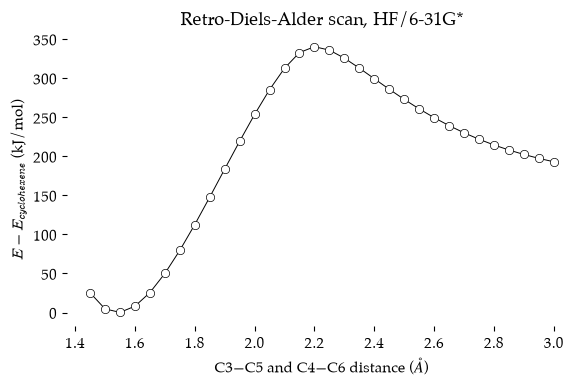

Highest point: 2.20 Angstrom, 340.25 kJ/mol above cyclohexene


In [8]:
scan_df = pd.DataFrame(scan)
scan_df.to_json("cyclohexene_scan_HF631Gs.json", orient="records", indent=2)

scan_df["Delta E"] = (scan_df["Energy"] - E_cyclohexene) * psi4.constants.hartree2kJmol

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))
ax.plot(scan_df["Distance"], scan_df["Delta E"], color="black", linewidth=0.7, marker="o",
        markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
ax.set_xlabel(r"C3$-$C5 and C4$-$C6 distance ($\AA$)")
ax.set_ylabel(r"$E - E_{cyclohexene}$ (kJ/mol)")
ax.set_title("Retro-Diels-Alder scan, HF/6-31G*")
plt.show()

top = scan_df.loc[scan_df["Energy"].idxmax()]
print(f"Highest point: {top['Distance']:.2f} Angstrom, {top['Delta E']:.2f} kJ/mol above cyclohexene")

| Line | Notes |
| :---- | :---- |
| `pd.DataFrame(scan)` | Turns the list of records into a *pandas* **dataframe**, a table with one row per scan point. |
| `.to_json(..., orient="records", indent=2)` | Saves the table as a JSON file, one record per scan point. |
| `scan_df["Delta E"] = ...` | A new column: the energy **relative** to optimized cyclohexene, in *kJ/mol*. |
| `scan_df["Energy"].idxmax()` | The **row label** of the highest energy. `scan_df.loc[...]` gets that row. |

The energy is lowest near 1.54 &Aring;, the length of the bonds in relaxed cyclohexene. The 1.55 &Aring; point is only 0.20 *kJ/mol* above cyclohexene. Squeezing the bonds to 1.45 &Aring; costs about 25 *kJ/mol*. Stretching them, the energy climbs steeply to a **maximum** at 2.20 &Aring;, 340.25 *kJ/mol* above cyclohexene, and then falls away again. By 3.00 &Aring; the energy is 192.96 *kJ/mol* above cyclohexene and the curve is flattening out as ethylene leaves. In the *GAMESS* book, the maximum was also at 2.20 &Aring;, 340 *kJ/mol* above the lowest scan point.

We observe that the **highest energy** occurs near 2.20 &Aring;. This is a good structure to use as the **starting point** for a transition state optimization. The [second notebook](092-ScanData.ipynb) of this chapter takes a closer look at the profile.

-----

## Transition State Optimization

We now have a **starting position** for a transition state optimization.

### The Hessian Calculation

As in the [butadiene chapter](../08-Butadiene/081-Butadiene.ipynb), we first check that our starting structure has an **imaginary vibration** pointing along the reaction coordinate. In the *GAMESS* book I set `RUNTYP=HESSIAN` with `VIBANL=.TRUE.` for this. In *Psi4* it is `psi4.frequency()`. We will also ask *Psi4* to write the vibrations to a *Molden* file that *Avogadro* can open.

In [9]:
psi4.core.clean_options()
psi4.set_options({"scf_type": "pk",
                  "normal_modes_write": True,
                  "writer_file_label": "diels_alder_ts_guess"})

ts = molecules[f"{top['Distance']:.2f}"].clone()
print(f"Starting C3-C5 distance: {bond_length(ts, 2, 4):.4f} Angstrom")

psi4.set_output_file("diels_alder_ts_guess_freq.out", False)

E_guess, wfn_guess = psi4.frequency("hf/6-31g*", molecule=ts, return_wfn=True)

freqs_guess = wfn_guess.frequencies().to_array()
print(f"Energy: {E_guess:.8f} Hartree")
print("Imaginary frequencies:", freqs_guess[freqs_guess < 0])
print("Lowest five:          ", np.round(freqs_guess[:5], 2))

Starting C3-C5 distance: 2.2000 Angstrom
Energy: -232.87960931 Hartree
Imaginary frequencies: [-910.30648080]
Lowest five:           [-910.31000000  162.66000000  260.89000000  319.74000000  415.84000000]


| Line | Notes |
| :---- | :---- |
| `psi4.core.clean_options()` | Clears **all** the options, including `ranged_distance` and `geom_maxiter`. We then set `scf_type` again. |
| `"normal_modes_write": True` | Writes the vibrations to a *Molden* file that ends in `.molden_normal_modes`. |
| `"writer_file_label": "diels_alder_ts_guess"` | The **start** of that file's name. *Psi4* adds a number (the process ID) and `.molden_normal_modes`. |
| `molecules[f"{top['Distance']:.2f}"].clone()` | A **copy** of the optimized structure from the highest point of the scan. |
| `psi4.frequency("hf/6-31g*", ...)` | Calculates the **Hessian** and the vibrational frequencies. `return_wfn=True` gives us the wavefunction, which holds the results. |
| `freqs_guess[freqs_guess < 0]` | Only the **negative** (imaginary) frequencies. |

There are 42 vibrations (3N &minus; 6 = 42 for 16 atoms). There is exactly **one** imaginary frequency, 910.31*i* cm<sup>&minus;1</sup>. All the others are real, starting at 162.66 cm<sup>&minus;1</sup>. The energy, &minus;232.87960931 Hartree, matches the energy in the `$HESS` group of the *GAMESS* Hessian job (&minus;232.8796092028 Hartree) to 1 &times; 10<sup>&minus;7</sup> Hartree. The imaginary frequency is large because the vibration involves making and breaking C&ndash;C bonds, not just twisting around one, as in the butadiene chapter (165*i* cm<sup>&minus;1</sup>).

Here is the imaginary vibration. Do the vectors **align** with the reaction coordinate?

In [10]:
show_vibration(wfn_guess, 0)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

The C3&ndash;C5 and C4&ndash;C6 bonds stretch and shrink **together**, in step. The ethylene part rocks toward and away from the ends of the butadiene part, and the CH<sub>2</sub> groups at C3, C4, C5 and C6 flap as the carbons switch between flat *sp<sup>2</sup>* and tetrahedral *sp<sup>3</sup>*. This is the reaction coordinate. This structure will lead to a **transition state**. You can also open the `diels_alder_ts_guess` file that ends in `.molden_normal_modes` in *Avogadro* to see every vibration and its arrows. We can now perform the saddle point optimization.

### The Transition State Optimization

In *GAMESS* I set `RUNTYP=SADPOINT` with `HESS=CALC` (calculate a Hessian at the start), a tight `OPTTOL=1e-05` and `NSTEP=200`. I also set `HSSEND=.t.` to calculate a final Hessian at the end, and I had to make yet another check job to generate internal coordinates so that the log file would report the bond lengths. Our version is below.

In [11]:
psi4.core.clean()
psi4.set_options({"normal_modes_write": False,
                  "opt_type": "ts",
                  "full_hess_every": 0,
                  "g_convergence": "gau_tight",
                  "geom_maxiter": 100})

psi4.set_output_file("diels_alder_ts.out", False)

E_ts, hist_ts = psi4.optimize("hf/6-31g*", molecule=ts, return_history=True)

print(f"Final energy: {E_ts:.8f} Hartree")
print("Steps taken: ", len(hist_ts["energy"]))
print("Point group: ", ts.schoenflies_symbol())
print(f"C3-C5 {bond_length(ts, 2, 4):.4f}   C4-C6 {bond_length(ts, 3, 5):.4f} Angstrom")

Optimizer: Optimization complete!
Final energy: -232.87960510 Hartree
Steps taken:  2
Point group:  cs
C3-C5 2.2023   C4-C6 2.2023 Angstrom


| Line | Notes |
| :---- | :---- |
| `"opt_type": "ts"` | Search for a **transition state** (a saddle point) instead of a minimum. This is `RUNTYP=SADPOINT` in *GAMESS*. |
| `"full_hess_every": 0` | Calculate the full **Hessian** once, at the start, and then update it with the gradients at each step. This is `HESS=CALC` in *GAMESS*. |
| `"g_convergence": "gau_tight"` | A **tighter** set of convergence criteria. The largest force must be below 1.5 &times; 10<sup>&minus;5</sup>, which plays the role of `OPTTOL=0.00001`, although the two tests are not defined the same way. |
| `"geom_maxiter": 100` | The most steps allowed. |

The saddle point was found in just 2 steps. We were almost exactly there already. The energy is &minus;232.87960510 Hartree, 0.011 *kJ/mol* **higher** than the starting structure. That is what we want: we climbed the last little bit to the top of the pass. The C3&ndash;C5 and C4&ndash;C6 bonds went from 2.2000 to 2.2023 &Aring;, and the structure is still *C<sub>s</sub>*. *GAMESS* also found the saddle point immediately, with a bond length of 2.2020 &Aring;.

Let us look at the convergence table.

In [12]:
search_file("diels_alder_ts.out", "~")

  2925: 	----------------------------------------------------------------------------------------------~
  2926: 	   Step    Total Energy     Delta E     Max Force     RMS Force      Max Disp      RMS Disp   ~
  2927: 	----------------------------------------------------------------------------------------------~
  2928: 	  Convergence Criteria              o    1.50e-05 *    1.00e-05 *    6.00e-05 *    4.00e-05 *~
  2929: 	----------------------------------------------------------------------------------------------~
  2930: 	     1    -232.87960931   -2.33e+02 o    5.41e-04      2.09e-04      3.87e-03      1.41e-03    ~
  3470: 	     2    -232.87960510    4.21e-06 o    6.80e-06 *    1.62e-06 *    3.36e-05 *    1.01e-05 *  ~


All four force and step criteria of `gau_tight` are active and all four were met (`*`) at step 2. The energy change is marked `o`, not used. The first step started with a largest force of 5.4 &times; 10<sup>&minus;4</sup>, small already, because the scan point was so close to the top.

### Is It Really a Transition State?

A true transition state has exactly **one** imaginary frequency. In *GAMESS*, `HSSEND=.t.` took care of this. We clear the options and calculate the frequencies at the new structure. We will write the vibrations to a *Molden* file again, so you can look at the transition state vibration in *Avogadro*.

In [13]:
psi4.core.clean()
psi4.core.clean_options()
psi4.set_options({"scf_type": "pk",
                  "normal_modes_write": True,
                  "writer_file_label": "diels_alder_ts"})

psi4.set_output_file("diels_alder_ts_freq.out", False)

E_ts_freq, wfn_ts = psi4.frequency("hf/6-31g*", molecule=ts, return_wfn=True)

freqs_ts = wfn_ts.frequencies().to_array()
print("Imaginary frequencies:", freqs_ts[freqs_ts < 0])
print("Lowest five:          ", np.round(freqs_ts[:5], 2))
print()
print(f"Barrier from cyclohexene: {(E_ts - E_cyclohexene) * psi4.constants.hartree2kJmol:.2f} kJ/mol")
show_vibration(wfn_ts, 0)

Imaginary frequencies: [-903.39921341]
Lowest five:           [-903.40000000  161.99000000  261.98000000  319.45000000  415.67000000]

Barrier from cyclohexene: 340.26 kJ/mol


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

There is exactly **one** imaginary frequency, 903.40*i* cm<sup>&minus;1</sup>, and all the others are real. We have a **transition state**. The barrier from cyclohexene is 340.26 *kJ/mol*, only 0.01 *kJ/mol* above the highest point of our scan. With 0.05 &Aring; steps, the scan had already found the top of the pass.

```{note}
The barrier we calculated is for the **retro**-Diels-Alder reaction, from cyclohexene to butadiene and ethylene. It is an **electronic** energy at the HF level of theory. Hartree-Fock is known to **overestimate** the barriers of pericyclic reactions because it leaves out electron correlation, which is especially important for the partly formed bonds in a transition state. Treat the number as a rough guide.
```

-----

## Discussion of the Reaction Coordinate

Let us **compare** the structures of the optimized cyclohexene, the optimized transition state and the scan point at 3.00 &Aring;. We will measure the C&ndash;C distances that change during the reaction and collect them in a table.

In [14]:
structures = {"cyclohexene": cyclohexene,
              "transition state": ts,
              "scan point 3.00": molecules["3.00"]}

rows = []
for name, mol in structures.items():
    rows.append({"Structure": name,
                 "C1-C2": bond_length(mol, 0, 1),
                 "C1-C3": bond_length(mol, 0, 2),
                 "C3-C5": bond_length(mol, 2, 4),
                 "C5-C6": bond_length(mol, 4, 5),
                 "C1-C3-C5": bond_angle(mol, 0, 2, 4)})

pd.DataFrame(rows).round(4)

,Structure,C1-C2,C1-C3,C3-C5,C5-C6,C1-C3-C5
0,cyclohexene,1.3200,1.5090,1.5411,1.5502,111.2699
1,transition state,1.3929,1.3773,2.2023,1.3830,102.5927
2,scan point 3.00,1.4742,1.3237,3.0000,1.3178,99.3679


| Line | Notes |
| :---- | :---- |
| `structures = {...}` | A **dictionary** of names and molecules. |
| `for name, mol in structures.items():` | Loops over the names and molecules together. |
| `pd.DataFrame(rows).round(4)` | A table of all the measurements, rounded to four decimals. |

Here are the same measurements from the *GAMESS* book.

| Structure | C1&ndash;C2 | C1&ndash;C3 | C3&ndash;C5 | C5&ndash;C6 | C1&ndash;C3&ndash;C5 |
| :---- | ----: | ----: | ----: | ----: | ----: |
| cyclohexene | 1.3200 | 1.5089 | 1.5412 | 1.5501 | 111.26 |
| transition state | 1.3930 | 1.3772 | 2.2020 | 1.3828 | 102.58 |
| scan point 3.00 | 1.4742 | 1.3237 | 3.0000 | 1.3178 | 99.24 |

The two programs agree to within 0.0003 &Aring; for every bond and 0.01&deg; for the angles of cyclohexene and the transition state. The only visible difference is the C1&ndash;C3&ndash;C5 angle at 3.00 &Aring; (99.37&deg; vs 99.24&deg;). Far from the transition state the energy surface is very flat, and the two optimizers stopped at slightly different places, with energies that differ by less than 10<sup>&minus;8</sup> Hartree.

The C5&ndash;C6 bond length is a C&ndash;C single bond in the cyclohexene with *sp<sup>3</sup>* carbons. Observe how the **bond length** changes from 1.55 to 1.32 &Aring; over the course of the **reaction**. The carbon atoms also clearly change from tetrahedral *sp<sup>3</sup>* to planar *sp<sup>2</sup>*. At the same time, the C1=C2 double bond becomes the **single** bond in the middle of butadiene, and the C1&ndash;C3 single bond becomes a **double** bond. In the transition state, all three are about halfway, near 1.38 to 1.39 &Aring;. The bonds are being made and broken **together**. That is what a **concerted** reaction looks like.

We can see that the ethylene group swings over the top of the butadiene terminal carbons as the reaction proceeds. The C1&ndash;C3&ndash;C5 bond angle is 111.27&deg; in the cyclohexene and ends up at 99.37&deg; at 3.00 &Aring;. This is **consistent** with the &pi;-orbital interactions between **frontier molecular orbitals**.

So what is the **reaction coordinate**, really? We have used the breaking bond distance as the *x*-axis. We could have used any of the bond **distances** as they all change during the reaction. We could have used the change in **hybridization** from tetrahedral *sp<sup>3</sup>* to planar *sp<sup>2</sup>* for carbon atoms. We could have used bond **angles** that changed. What is the best way to represent the progress of the reaction? You get to decide.

-----

## IRC Calculations

Now that we have an optimized **transition state** structure we can perform an intrinsic reaction coordinate (IRC) calculation. This will follow the imaginary vibration in one direction down to the ground state. We can then **repeat** the IRC in the **other direction**. The benefit of this calculation is that it will **follow the gradient** and is not limited to any specific series of coordinate values. If bond lengths change with different timings as a reaction proceeds then we will follow that groove. This will give us a more accurate picture of the journey from reactant to product (assuming you believe that computational chemistry relates to reality).

The best **reason** to perform the IRC calculation is that it can be used to make a **movie** of the reaction. So let us give it a try.

### Setting Up and Running

In *GAMESS*, the IRC needed some hand editing of the input file. I added an `$IRC` group,

```text
$IRC PACE=GS2 OPTTOL=0.0001 MXOPT=300 STRIDE=0.30
     SADDLE=.TRUE. TSENGY=.TRUE. FORWRD=.TRUE. NPOINT=300 $END
```

then copied hundreds of lines of orbitals (`$VEC`) and the Hessian (`$HESS`) from the `.dat` file of the Hessian job into the input file. `PACE=GS2` chose the Gonzalez-Schlegel second order method. Each step moves a fixed distance along the path (`STRIDE`) and then does a small **constrained optimization** on a sphere around the new point. *Psi4*'s optimizer uses the **same** Gonzalez-Schlegel method, so the options are short. And, like *GAMESS*, we will hand it the **Hessian** that we have already calculated.

| *GAMESS* `$IRC` | *Psi4* option | Meaning |
| :---- | :---- | :---- |
| `RUNTYP=IRC` | `"opt_type": "irc"` | Follow the reaction path. |
| `FORWRD=.TRUE.` / `.FALSE.` | `"irc_direction": "forward"` / `"backward"` | Which way to leave the saddle point. Which direction is called &ldquo;forward&rdquo; is meaningless. We run **two jobs**, one in each direction. |
| `STRIDE=0.30` | `"irc_step_size": 0.3` | The distance between points on the path, in **mass-weighted** coordinates (amu<sup>&frac12;</sup> bohr) in both programs. Smaller steps follow the path more accurately, and take longer. Have you got the time? |
| `NPOINT=300` | `"irc_points": 10` | The **most** points to calculate. Both programs also stop early if they decide they have reached a minimum. See the warning below for why we stop at 10. |
| `SADDLE=.TRUE.` + `$HESS` | `irc.HX = hessian` | We give the IRC the **Hessian** from our transition state frequency calculation, `wfn_ts.hessian()`. Its lowest vibration tells the IRC which way is downhill. |

```{warning}
*Psi4*'s IRC works well near the transition state but can get **stuck** further down the hill. In my first run of this notebook, the IRC toward butadiene and ethylene could not finish the little constrained optimization for its 11th point. It tried again, and again, and then gave up with the error `OptError: Maximum dynamic_level reached`, and the notebook stopped. So we take only **10 points** in each direction (3.0 amu<sup>&frac12;</sup> bohr of path), which covers the interesting part where bonds are made and broken, and then finish the trip downhill with an ordinary optimization. If a direction is still running after 20 minutes, interrupt the kernel and lower `irc_points`.
```

### Why We Drive the IRC Ourselves

The easy way to run an IRC is `psi4.optimize()` with `"opt_type": "irc"`. Each time you do that, *Psi4* calculates a **new** Hessian at the transition state and takes the transition state vibration from it. &ldquo;Forward&rdquo; means moving along that vibration, and &ldquo;backward&rdquo; means moving against it. But the **sign** of a vibration is arbitrary. The arrows can point either way and describe the same motion. *Psi4*'s optimizer picks the sign from the largest number in the vibration. In our mirror-symmetric molecule, the largest numbers come in **pairs**, one positive and one negative and equal in size. Which one wins is decided by the last few digits, which change a little from one Hessian calculation to the next. In one of my runs, the forward and backward IRCs both set off toward butadiene and ethylene, and nobody went to cyclohexene!

The cure is to calculate the Hessian **once** and give the **same** Hessian to both runs. Then &ldquo;forward&rdquo; and &ldquo;backward&rdquo; are truly opposite. That is exactly what `$HESS` did in *GAMESS*. *Psi4*'s `psi4.optimize()` does not let us hand it a Hessian, so we will talk to its optimizer, *optking*, directly. This is what `psi4.optimize()` does behind the scenes, in a loop.

1. Calculate the energy and gradient at the current structure with `psi4.gradient()`.
2. Give them to *optking*, plus the Hessian when it asks for one.
3. Let *optking* take a step, and move the molecule to the new structure.
4. Stop when *optking* says it has finished.

*optking* writes the structure and energy of every point on the path to a file named `irc_traj.` followed by a number and `.xyz`. The number is the same for both runs, so the second run would **overwrite** the first. We will rename the file as soon as each run finishes. Since we will do the same thing twice, we will write a small function.

In [15]:
import optking

def run_irc(ts_mol, direction, hessian):
    psi4.core.clean()
    psi4.core.clean_options()
    psi4.set_options({"scf_type": "pk"})
    psi4.set_output_file(f"diels_alder_irc_{direction}.out", False)

    mol = ts_mol.clone()
    irc = optking.opt_helper.CustomHelper(mol, params={"opt_type": "irc",
                                                       "irc_direction": direction,
                                                       "irc_step_size": 0.3,
                                                       "irc_points": 10,
                                                       "write_trajectory": True},
                                        dtype=2)
    for step in range(300):
        G = psi4.gradient("hf/6-31g*", molecule=mol)
        irc.E = psi4.variable("CURRENT ENERGY")
        irc.gX = G.np
        if "hessian" in irc.calculations_needed():
            irc.HX = hessian
        irc.molsys.geom = mol.geometry().np
        irc.compute()
        irc.take_step()
        mol.set_geometry(psi4.core.Matrix.from_array(irc.molsys.geom))
        mol.update_geometry()
        if irc.status() == "CONVERGED":
            break
    irc.close()

    for f in Path(".").glob("irc_traj.*.xyz"):
        f.rename(f"diels_alder_irc_{direction}.xyz")
    print(f"{direction}: {step + 1} gradients")
    return mol

H_ts = wfn_ts.hessian().np

mol_forward = run_irc(ts, "forward", H_ts)
mol_backward = run_irc(ts, "backward", H_ts)

print(f"Forward end:  C3-C5 {bond_length(mol_forward, 2, 4):.4f} Angstrom")
print(f"Backward end: C3-C5 {bond_length(mol_backward, 2, 4):.4f} Angstrom")

forward: 37 gradients
backward: 36 gradients
Forward end:  C3-C5 1.6628 Angstrom
Backward end: C3-C5 2.5984 Angstrom


| Line | Notes |
| :---- | :---- |
| `import optking` | Loads *Psi4*'s optimizer as its own *Python* package, so we can talk to it directly. |
| `def run_irc(ts_mol, direction, hessian):` | Our function takes the transition state molecule, a direction (`"forward"` or `"backward"`) and the Hessian. |
| `psi4.core.clean_options()` | Start from a clean set of options, so nothing from the transition state search sneaks in. |
| `mol = ts_mol.clone()` | A **copy** of the transition state, so that both runs start from the same place. |
| `optking.opt_helper.CustomHelper(mol, params={...})` | Sets up an *optking* optimization of `mol` with our IRC options. `"write_trajectory": True` asks for the `.xyz` file of the path. |
| `dtype=2` | Use version 2 of the data format that *optking* and *Psi4* use to pass molecules back and forth. `psi4.optimize()` does this for us. Without it, newer versions of *Python* (3.14 and up) stop with an error about `pydantic.v1`. |
| `for step in range(300):` | Repeat the loop at most 300 times, so a stuck IRC cannot run forever. |
| `psi4.gradient("hf/6-31g*", molecule=mol)` | The **gradient** (the slope of the energy) at the current structure. The energy is saved in the *Psi4* variable `CURRENT ENERGY`. |
| `irc.E = ...`, `irc.gX = G.np` | Hands the energy and the gradient to *optking*. |
| `if "hessian" in irc.calculations_needed():` | At the transition state, *optking* asks for a Hessian. Instead of calculating a new one, we give it ours: `irc.HX = hessian`. |
| `irc.molsys.geom = mol.geometry().np` | Makes sure *optking* has the same coordinates as *Psi4*. |
| `irc.compute()`, `irc.take_step()` | *optking* processes the gradient and takes one step along the path (or one step of the little constrained optimization). |
| `mol.set_geometry(...)` | Moves our molecule to *optking*'s new structure. |
| `irc.status() == "CONVERGED"` | *optking* has finished the path (reached `irc_points`, or decided it has reached the bottom). `break` leaves the loop. |
| `irc.close()` | Finishes up and writes the `irc_traj` file. |
| `Path(".").glob("irc_traj.*.xyz")` | Finds any file in this folder whose name matches the pattern. `*` stands for any text (here, the number). |
| `f.rename(...)` | **Renames** the file to `diels_alder_irc_forward.xyz` or `diels_alder_irc_backward.xyz`. |
| `H_ts = wfn_ts.hessian().np` | The Hessian from the frequency calculation at the transition state, as a 48 &times; 48 *NumPy* array (3 coordinates &times; 16 atoms). Both runs get this same Hessian. |

This cell took about 3 minutes on my laptop. Each point on the path needs several gradients for its little constrained optimization, but no new Hessian is calculated.

This time the two directions really are opposite. The forward run went toward **cyclohexene** and stopped with the C3&ndash;C5 bonds at 1.6628 &Aring;. The backward run went toward **butadiene and ethylene** and stopped with them at 2.5984 &Aring;. Each run took 10 points along the path (it stopped because it reached `irc_points`), and each needed 36 or 37 gradients, about three or four per point for the little constrained optimizations. With the same Hessian, which side is called &ldquo;forward&rdquo; is still arbitrary, but the two runs can no longer both go the same way.

### Where Does the Path Lead?

Our IRC stopped after 10 points (or earlier, if *Psi4* decided it had reached the bottom of the valley). The structures at the ends of the path are not minima. They are just the places where the IRC stopped.

A common way to finish the job is to take the end of the path and run an ordinary **optimization** from there. If our transition state really connects cyclohexene with butadiene and ethylene, then the end on the cyclohexene side should roll down to the cyclohexene that we optimized at the start of the chapter. (The other end would slowly drift apart into separate butadiene and ethylene molecules, which could take a very long time, so we will leave it alone.)

In [16]:
if bond_length(mol_forward, 2, 4) < bond_length(mol_backward, 2, 4):
    end = mol_forward.clone()
else:
    end = mol_backward.clone()

psi4.core.clean()
psi4.core.clean_options()
psi4.set_options({"scf_type": "pk"})
psi4.set_output_file("diels_alder_irc_end_opt.out", False)

E_end, hist_end = psi4.optimize("hf/6-31g*", molecule=end, return_history=True)

print(f"Final energy: {E_end:.8f} Hartree   ({len(hist_end['energy'])} steps)")
print(f"Cyclohexene:  {E_cyclohexene:.8f} Hartree")
print(f"Difference:   {(E_end - E_cyclohexene) * psi4.constants.hartree2kJmol:.3f} kJ/mol")
print(f"C3-C5 {bond_length(end, 2, 4):.4f} Angstrom   C1-C3-C5 {bond_angle(end, 0, 2, 4):.2f} degrees")

Optimizer: Optimization complete!
Final energy: -233.00920357 Hartree   (8 steps)
Cyclohexene:  -233.00920358 Hartree
Difference:   0.000 kJ/mol
C3-C5 1.5411 Angstrom   C1-C3-C5 111.26 degrees


| Line | Notes |
| :---- | :---- |
| `if bond_length(mol_forward, 2, 4) < ...` | We do not know in advance which direction *Psi4* called &ldquo;forward&rdquo;, so we pick the end with the **shorter** C3&ndash;C5 bond. That is the cyclohexene side. |
| `psi4.optimize("hf/6-31g*", molecule=end, ...)` | An ordinary optimization, with no constraints and no IRC, starting from the end of the path. |

In 8 steps the end of the path rolled down to &minus;233.00920357 Hartree, the same as the cyclohexene we optimized at the start of the chapter (0.000 *kJ/mol* difference), with C3&ndash;C5 bonds of 1.5411 &Aring; and a C1&ndash;C3&ndash;C5 angle of 111.26&deg;. Our transition state really does connect *C<sub>s</sub>* cyclohexene with butadiene and ethylene.

### Assembling the Path

Each `.xyz` file holds one **frame** per IRC point. Each frame is the number of atoms, a title line with the step number and the energy, and one line per atom. Here is the start of one.

In [17]:
with open("diels_alder_irc_forward.xyz") as f:
    lines = f.readlines()
print("".join(lines[:20]))

16
IRC trajectory step: 0. E: -232.8796050957523
C     0.352049    -2.449271     1.316106
C     0.352049    -2.449271    -1.316106
C    -0.978255    -0.671396     2.674075
C    -0.978255    -0.671396    -2.674075
C     0.638756     2.911281     1.306731
C     0.638756     2.911281    -1.306731
H     1.745128    -3.576233     2.282105
H     1.745128    -3.576233    -2.282105
H     2.380488     2.640430     2.308612
H     2.380488     2.640430    -2.308612
H    -0.756086    -0.582699     4.694192
H    -0.756086    -0.582699    -4.694192
H    -0.760525     3.998290     2.301398
H    -0.760525     3.998290    -2.301398
H    -2.763892     0.013561     2.005511
H    -2.763892     0.013561    -2.005511
16
IRC trajectory step: 1. E: -232.88545598473152



The title line reads `IRC trajectory step: 1. E: ...`. Step 0 is the transition state. Look closely at the coordinates. They are about twice as large as they should be. An `.xyz` file is supposed to be in &Aring;ngstroms, but *Psi4* writes this one in **Bohr**. We will have to convert them. The forward run counts **up** from zero and the backward run counts **down** (&minus;1, &minus;2, &hellip;), so if we sort all the frames by step number we get the whole path from one end to the other. Let us write a function that reads the file into a list of frames.

In [18]:
def read_irc(filename):
    with open(filename) as f:
        lines = f.readlines()

    frames = []
    i = 0
    while i < len(lines) and lines[i].strip() != "":
        natom = int(lines[i])
        title = lines[i + 1].split()
        atoms = lines[i + 2:i + 2 + natom]
        symbols = [atom.split()[0] for atom in atoms]
        xyz = np.array([[float(v) for v in atom.split()[1:4]] for atom in atoms])
        xyz = xyz * psi4.constants.bohr2angstroms

        text = f"{natom}\n{lines[i + 1].strip()}\n"
        for symbol, (x, y, z) in zip(symbols, xyz):
            text = text + f"{symbol} {x:10.6f} {y:10.6f} {z:10.6f}\n"

        frames.append({"Step": int(float(title[3])),
                       "Energy": float(title[5]),
                       "text": text,
                       "xyz": xyz})
        i = i + 2 + natom
    return frames

forward = read_irc("diels_alder_irc_forward.xyz")
backward = read_irc("diels_alder_irc_backward.xyz")

path = sorted(backward[1:] + forward, key=lambda frame: frame["Step"])
print(len(forward), "forward points,", len(backward), "backward points,", len(path), "on the whole path")

11 forward points, 11 backward points, 21 on the whole path


| Line | Notes |
| :---- | :---- |
| `while i < len(lines) and lines[i].strip() != "":` | Keep reading frames until we reach the end of the file (or a blank line). `i` is the line where the current frame starts. |
| `natom = int(lines[i])` | The first line of a frame is the number of atoms. |
| `title = lines[i + 1].split()` | The title line, split into words: `['IRC', 'trajectory', 'step:', '1.', 'E:', '-232.8...']`. Word 3 is the step and word 5 is the energy. |
| `int(float(title[3]))` | `'1.'` is not a whole number to *Python*, so we read it as a decimal number first. |
| `symbols = [...]` | The element symbol of each atom, the first word on each atom line. |
| `xyz = np.array(...)` | The *x*, *y*, *z* coordinates of every atom, as a 16 &times; 3 array. |
| `xyz * psi4.constants.bohr2angstroms` | Converts the coordinates from Bohr to **&Aring;ngstroms**. |
| `text = ...` | The frame written out again as *xyz* text, now in &Aring;ngstroms. We will need it for the movie. `\n` starts a new line. |
| `i = i + 2 + natom` | Jump to the start of the next frame. |
| `backward[1:] + forward` | Both lists joined together. `[1:]` skips the first backward frame, which is the transition state again. |
| `sorted(..., key=lambda frame: frame["Step"])` | Sorts the frames by their step number. `lambda frame: frame["Step"]` is a tiny function that tells `sorted()` what to sort by. |

Now we can make a table of the whole path. We will measure the breaking (or forming) C3&ndash;C5 bond and the C5&ndash;C6 bond that becomes the double bond of ethylene. Our `bond_length()` function wants a *Psi4* molecule, but here we have plain coordinates, so we take the distance between the two rows of the `xyz` array directly. The *x*-axis will be the **distance along the path**, the step number times the step size.

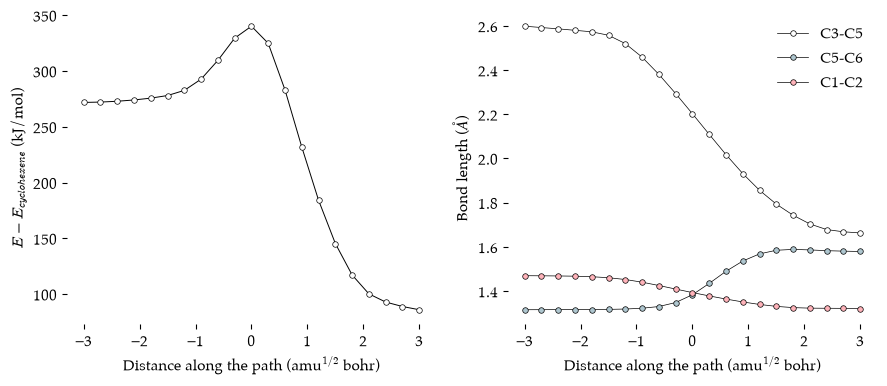

In [19]:
irc = pd.DataFrame({
    "Step": [frame["Step"] for frame in path],
    "Path distance": [frame["Step"] * 0.3 for frame in path],
    "Energy": [frame["Energy"] for frame in path],
    "C3-C5": [np.linalg.norm(frame["xyz"][2] - frame["xyz"][4]) for frame in path],
    "C5-C6": [np.linalg.norm(frame["xyz"][4] - frame["xyz"][5]) for frame in path],
    "C1-C2": [np.linalg.norm(frame["xyz"][0] - frame["xyz"][1]) for frame in path],
})
irc["Delta E"] = (irc["Energy"] - E_cyclohexene) * psi4.constants.hartree2kJmol
irc.to_json("diels_alder_irc_HF631Gs.json", orient="records", indent=2)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9,4))

axs[0].plot(irc["Path distance"], irc["Delta E"], color="black", linewidth=0.7, marker="o",
            markersize=4, markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
axs[0].set_xlabel(r"Distance along the path (amu$^{1/2}$ bohr)")
axs[0].set_ylabel(r"$E - E_{cyclohexene}$ (kJ/mol)")

for column, color in [("C3-C5", "white"), ("C5-C6", "#AEC6CF"), ("C1-C2", "#FFB3BA")]:
    axs[1].plot(irc["Path distance"], irc[column], color="black", linewidth=0.5, marker="o",
                markersize=4, markerfacecolor=color, markeredgecolor="black",
                markeredgewidth=0.5, label=column)
axs[1].set_xlabel(r"Distance along the path (amu$^{1/2}$ bohr)")
axs[1].set_ylabel(r"Bond length ($\AA$)")
axs[1].legend()

plt.show()

| Line | Notes |
| :---- | :---- |
| `[frame["Step"] for frame in path]` | A **list comprehension**: a list of the step numbers of every frame on the path. Each column of the table is made the same way. |
| `frame["Step"] * 0.3` | The distance along the path in mass-weighted coordinates. Every step is 0.3 amu<sup>&frac12;</sup> bohr (our `irc_step_size`). |
| `np.linalg.norm(frame["xyz"][2] - frame["xyz"][4])` | The C3&ndash;C5 distance. Rows 2 and 4 of the coordinate array are atoms 3 and 5. |
| `irc.to_json(...)` | Saves the path as a JSON file. |
| `for column, color in [...]` | Draws the three bond lengths on the second panel with three different marker colours. |

The energy profile (left) has its **maximum** at the transition state (340.26 *kJ/mol* above cyclohexene) and falls away smoothly on both sides, but not symmetrically. On the cyclohexene side (positive distances) the energy drops steeply, to 86.03 *kJ/mol* above cyclohexene at the end of the path. On the butadiene + ethylene side it drops more gently and then levels off at about 272 *kJ/mol*. Over the last five steps on that side the energy changes by only 6 *kJ/mol*. The ethylene is drifting away over a nearly flat landscape. That flatness is probably why *Psi4*'s IRC struggled to make progress in this direction.

The bond lengths (right) all change **together**, which is what a concerted reaction looks like. Within 0.6 amu<sup>&frac12;</sup> bohr on either side of the transition state, the C3&ndash;C5 bond (open circles) changes from 2.02 to 2.38 &Aring;, the C5&ndash;C6 bond (blue) from 1.49 to 1.33 &Aring; and the C1&ndash;C2 bond (pink) from 1.36 to 1.42 &Aring;. Much of the change in the &pi; bonds happens in this short stretch of path near the top. At the product end, C5&ndash;C6 is 1.315 &Aring; (ethylene's C=C) and C1&ndash;C2 is 1.469 &Aring; (the single bond in the middle of butadiene).

Two things surprised me on the cyclohexene side. The C5&ndash;C6 bond **overshoots**. It reaches 1.588 &Aring;, longer than its 1.550 &Aring; in relaxed cyclohexene, before the end of the path. And the end of the path, with C3&ndash;C5 at 1.66 &Aring;, is still 86 *kJ/mol* above cyclohexene, while the relaxed scan point at 1.65 &Aring; is only 25 *kJ/mol* above it. The IRC follows the steepest way down from the transition state, which is not the same as the lowest-energy structure at each bond length. The rest of the molecule has not caught up yet. The ordinary optimization in the previous section took care of that.

### Visualizing the IRC

In the *GAMESS* book, I opened the log file of the forward run in *MacMolPlt*, added the frames from the backward run (with `Make these points negative` checked), and dragged the scrubber at the bottom of the window to **play the movie**. We already have the frames in order. All we need is to join them into one multi-frame `.xyz` file and give it to *py3Dmol*.

In [20]:
movie = "".join(frame["text"] for frame in path)

with open("diels_alder_irc.xyz", "w") as f:
    f.write(movie)

view = py3Dmol.view(width=400, height=300)
view.addModelsAsFrames(movie, "xyz")
view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
view.setBackgroundColor("#f2f2f2")
view.animate({"loop": "backAndForth", "interval": 100})
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `"".join(frame["text"] for frame in path)` | All the frames, in order, joined into one long block of text. |
| `open("diels_alder_irc.xyz", "w")` | Saves the movie as a file. You can open `diels_alder_irc.xyz` in *Avogadro* and play it with the animation tool. |
| `view.addModelsAsFrames(movie, "xyz")` | Loads **every** frame into the viewer as one frame of an animation. |
| `view.animate({"loop": "backAndForth", "interval": 100})` | Plays the frames forward and then backward, over and over, one frame every 100 milliseconds. |

**Watch** how the *sp<sup>3</sup>* carbons convert to *sp<sup>2</sup>* as the bonds break. Also **see** how the ethylene moves to a more vertical angle over the butadiene as the bonds break. **Spin** the structure with your mouse and **watch** the process from different sides. Can you **see** bond lengths change as &pi;-bonds change to &sigma;-bonds and vice versa?

```{note}
*py3Dmol* decides where to draw bonds from the distances between atoms. Watch the C3&ndash;C5 and C4&ndash;C6 bonds **appear** or **vanish** as the atoms move apart. The calculation knows nothing about these sticks. They are just a picture.
```

### A Longer Movie

Our IRC movie only covers the part of the path near the transition state. We have another series of structures that covers the **whole** reaction: the 32 points of our relaxed scan, from 1.45 to 3.00 &Aring;. They are not on the true reaction path (each one was forced to a bond length we chose), but they make a good movie too. *Psi4* will write any molecule as *xyz* text with `save_string_xyz_file()`, so we can join them in the same way.

In [21]:
scan_movie = "".join(molecules[f"{d:.2f}"].save_string_xyz_file() for d in distances)

with open("cyclohexene_scan.xyz", "w") as f:
    f.write(scan_movie)

view = py3Dmol.view(width=400, height=300)
view.addModelsAsFrames(scan_movie, "xyz")
view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
view.setBackgroundColor("#f2f2f2")
view.animate({"loop": "backAndForth", "interval": 100})
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `molecules[f"{d:.2f}"].save_string_xyz_file()` | Each stored scan structure as *xyz* text, with the number of atoms and a title line, ready to be a frame. |
| `for d in distances` | In order from 1.45 to 3.00 &Aring;. |

The two movies tell the same story in different ways. The IRC movie covers only the part of the path near the top of the barrier, from C3&ndash;C5 = 1.66 to 2.60 &Aring;, in 21 frames that are evenly spaced in **mass-weighted** distance. Most of the motion is packed into a few frames near the transition state, and the ends move slowly. The scan movie covers the whole range from 1.45 to 3.00 &Aring; in 32 frames that are evenly spaced in **bond length**, and every frame is a relaxed structure, so it looks smoother but it is not the true path the molecules would follow.

### A Note About Options

The true power of *Psi4* can be accessed through the many, many, **many options** available. We have used a handful of the optimizer's options to **improve** our transition state search and IRC calculation. I learned about these options by digging through the [*Psi4* documentation](https://psicode.org/psi4manual/master/optking.html) and reading useful web posts by others who are writing similar educational articles. See [here](https://medium.com/swlh/introduction-to-molecular-modelling-part-5-intrinsic-reaction-coordinate-af7ca328d88d) or [here](http://molecularmodelingbasics.blogspot.com/2009/10/get-reaction-intrinsic-reaction.html) for some examples. Should I have simply left it to them? Am I reinventing the wheel? Yes, but it's my wheel.

-----

## Summary

These are the operations that we have performed over the course of this activity.

1.	**Build and Optimize** *C<sub>s</sub>* cyclohexene. We wrote the eight symmetry-unique atoms and let *Python* add their mirror images. *Psi4* found the *C<sub>s</sub>* symmetry and kept it throughout the optimization.
2.	**Scan** the reaction coordinate. We used the `ranged_distance` option to hold the C3&ndash;C5 and C4&ndash;C6 bonds at 32 lengths between 1.45 and 3.00 &Aring;, starting each optimization from the previous structure, and saved the results to a JSON file.
3.	**Evaluate the vibrations** at the top of the scan and find the **imaginary vibration** that points along the reaction coordinate.
4.	**Optimize the transition state** with `opt_type` `ts` and confirm that it has exactly one imaginary frequency.
5.	**Compare** the bond lengths and angles of cyclohexene, the transition state and the separated products.
6.	**Follow the IRC** downhill in both directions from the transition state, assemble the path, plot the energy and the bond lengths along it and **make a movie** of the reaction.

The scan data is processed in the [second notebook](092-ScanData.ipynb) of this chapter.

-----

## A Challenge

### The Activity

#### Make It Break the Rules

We know that Diels-Alder reactions proceed with *suprafacial-suprafacial* (*ss*) **stereochemistry**. We can also obey the Woodward-Hoffmann orbital symmetry rules for this reaction with an *antarafacial-antarafacial* (*aa*) process. This process already has a starting point, the half-chair *C<sub>2</sub>* cyclohexene.

Optimize the structure of *C<sub>2</sub>* cyclohexene. Then use it as a **starting point** for a reaction coordinate scan **enforcing** *C<sub>2</sub>* symmetry. Can you optimize the *C<sub>2</sub>* transition state? If so, can an IRC be performed? It would be cool to **compare** the movies for the two reactions. Compare a plot of the potential energies across the reaction coordinate and **comment** on whether the *ss* or the *aa* is faster.

I dare you. No, I double-dog-dare you. Now you **cannot refuse** my challenge.

```{admonition} Hints
:class: dropdown
- Build the half-chair in *Avogadro*, optimize it with a force field and save it as an *xyz* file. Paste the coordinates into `psi4.geometry()`. If *Psi4* does not report *C<sub>2</sub>* symmetry, use `mol.symmetrize(0.05)` to tidy up the coordinates, or add the line `symmetry c2` to the geometry.
- Use `show_numbers()` to find the atom numbers of the two breaking bonds in **your** structure. They will probably not be 3,5 and 4,6.
- Check that every point of your scan **keeps** the *C<sub>2</sub>* symmetry with `mol.schoenflies_symbol()`.
- Optimize the half-chair first, then compare its energy with the boat. Which is the lower?
```

#### Other Reactions

Can you take the methods **demonstrated** in this chapter and create an IRC for a **conrotatory** and a **disrotatory** electrocyclic reaction? Make the movie. All we really want to do is direct.

Can you create an IRC of a [1,5]-H-shift **sigmatropic rearrangement**? Also try a [3,3] rearrangement. Model the **Claisen** rearrangement and the **Cope** rearrangement. Compare bond lengths in the transition states and apply **Hammond's postulate** when discussing these observations. Make the movies. They might go viral.

### The Report

Write a short report on the *C<sub>2</sub>* challenge (or one of the other reactions). Include
- the energies of the *C<sub>s</sub>* and *C<sub>2</sub>* cyclohexene conformers, and their difference in *kJ/mol*
- a plot of your reaction coordinate scan, with the *C<sub>s</sub>* scan from this chapter on the same axes
- the transition state energy, its imaginary frequency and a table of its key bond lengths
- the energy plot of your IRC, and a sentence or two on what you see in the movie
- your conclusion. Which pathway is faster, and by how much? Is that what the Woodward-Hoffmann rules lead you to expect?

```{warning} AI Statement
:class: dropdown
This page is an adaptation of the "Diels-Alder Reaction" chapter of my [previous web book on using *GAMESS*](https://blinkletter.github.io/UsingGAMESS). About **a quarter** of the text is **my own work**, carried over word for word or lightly edited, including the introduction, the discussion of the boat and half-chair conformers, the reaction coordinate and the IRC, and the challenges. The **rest of the page** was written by an **LLM system** at my request. I asked it to translate the *GAMESS* input files, *bash* scripts and *MacMolPlt* steps into *Psi4* and *Python*. The *Python* code, the line-by-line explanations of it, the comparisons of the *GAMESS* and *Psi4* options, the analysis of the output and the new commentary were written by the LLM. The calculations were run by me on my own computer, and the numbers quoted in the text come from those calculations.
```